#### Define a few parameters and functions

##### Requirements
This python 3 notebook should only require numpy, pandas, and scipy to do the data analysis, and matplotlib to make the figures. 

It was originally run with python 3.11.5, matplotlib 3.8.0, numpy 1.24.3, scipy 1.11.3 and pandas 2.1.1

In [1]:
import numpy as np, pandas as pd, scipy.special as ss, cmath

# set markersize for plotting later
markersize = 30
# set a standard water density and sediment density (kg/m^3)
rho, rhos = 995, 2650
# set constants: gravitational acceleration (m/s^2), kinematic viscosity (m^2/s), von Karman constant
g, nu, kappa = 9.81, 1e-6, 0.41

# MPM function with best fit parameters as described in paper
wp_func = lambda x: 4.61*(x-0.051)**1.5
wp_inv_func = lambda x: (x/4.61)**(2/3) + 0.051

# function to calculate the hydraulic radius correction factor
# inputs: alpha = W/H
def calc_FR(alpha): 
    return 1/(1 + 2/alpha)

# function to calculate the Vanoni-Brooks correction factor
# inputs: f = gRS/V^2, alpha = W/H, Re = VR/nu
def calc_FVB(f, alpha, Re, output='FVB'):
        # define constants
        a, b = 0.018409368, 0.224072094
        
        # calculate the ratio of wall friction to total friction (tau_wall/tau)
        twt = a * np.real(ss.lambertw(b * (Re/f)**(1/3)))**(-2) / f
        
        # output the correction factor
        if output == 'FVB':
            return 1 - twt / (1 + alpha/2)
        
        # output just the ratio of wall friction to total friction (tau_wall/tau)
        elif output == 'twt':
            return twt

# function to calculate the Guo correction factor
# inputs: f = gRS/V^2, alpha = W/H, ro = 30H/ks = 15H/D50
def calc_FG(f, alpha, ro, output='FG'):
        # define constants and important functions
        beta = (1/kappa) * (3/4 - 1/np.pi**2)
        phi = np.exp(-(alpha/np.pi)**(3/2))
        psi = np.sqrt(2/alpha) * (np.log(ro*np.exp(-1))/kappa - (1 + phi)**3/12/kappa + ((1 + np.sqrt(phi))/2)*(1+np.sin(np.pi*phi)/(np.pi*(1+phi))))
        
        # calculate the ratio of wall friction to total friction (tau_wall/tau)
        # two different ways to handle inputs depending on if they are arrays or not
        try:
            tcomplex = np.array([cmath.sqrt(xi) for xi in f*(1+alpha/2)*(psi**2 + beta**2) - 1])
        except:
            tcomplex = cmath.sqrt(f*(1+alpha/2)*(psi**2 + beta**2) - 1)
        
        twt = np.real((psi*tcomplex - beta)**2) / ((psi**2 + beta**2)**2 * f)
            
        if output == 'FG':         
            return 1 - twt/(1+alpha/2)
        
        elif output == 'twt':
            return twt

#### Load data sources

In [2]:
# Load the four datasets (kept in 02_data/, alongside their data dictionaries).
# Note: deal_dataset_S3.csv and deal_dataset_S4.csv contain two extra header rows
# (row 1: column descriptions, row 2: units); skiprows=[1, 2] skips them so columns load as numeric.
df = pd.read_csv('../02_data/deal_dataset_S3.csv', skiprows=[1, 2])
df_table_1 = pd.read_csv('../02_data/deal_dataset_S1.csv')
df_table_2 = pd.read_csv('../02_data/deal_dataset_S2.csv')
df_river = pd.read_csv('../02_data/deal_dataset_S4.csv', skiprows=[1, 2])

#### Tables

##### Table 1

In [3]:
# df_table_1.style
# print out table with set number of decimal places for each column
df_table_1.style.format({
    'Flume width (m)': '{:.3f}',
    'Mean flow depth (m)': '{:.3f}',
    'Water surface slope (m/m)': '{:.4f}',
    'Fluid flux (m3/s)': '{:.4f}',
    'Sediment mass flux (kg/s)': '{:.4f}'})

,Sediment kind,Flume width W (m),Flow depth H (m),Water surface slope S (m/m),Fluid flux Q (m3/s),Sediment mass flux qs (kg/s)
0,sphere,0.065000,0.054250,0.018600,0.002842,0.011591
1,sphere,0.065000,0.052000,0.015400,0.002842,0.006088
2,sphere,0.065000,0.054875,0.013100,0.002842,0.001759
3,sphere,0.065000,0.041250,0.033600,0.002842,0.041159
4,gravel,0.065000,0.050000,0.027200,0.002842,0.026513
5,gravel,0.065000,0.053375,0.015400,0.002842,0.004428
6,gravel,0.065000,0.053750,0.014400,0.002842,0.001406
7,gravel,0.065000,0.045250,0.025200,0.002842,0.016104
8,gravel,0.065000,0.050000,0.021600,0.002842,0.008876


<!-- ##### Table 2 -->

In [4]:
df_table_2.style.format({
    'Sediment density (kg/m3)': '{:.1f}',
    'Long grain axis (m)': '{:.4f}',
    'Middle grain axis (m)': '{:.4f}',
    'Short grain axis (m)': '{:.4f}',
    'VES diameter (m)': '{:.4f}',
    'Corey shape factor': '{:.2f}',
    'Drag coefficient': '{:.2f}',
    'VES drag coefficient': '{:.2f}',
    'Bulk coeff. of friction': '{:.2f}',
    'Flume slope': '{:.4f}',
    'Grain shape corr. factor': '{:.3f}'})

,Sediment kind,spheres,gravel
0,Sediment density (kg/m3),2557.664533,2470.921301
1,Long grain axis (m),0.004900,0.005775
2,Middle grain axis (m),0.004900,0.004380
3,Short grain axis (m),0.004900,0.003349
4,VES diameter (m),0.004946,0.004110
5,Corey shape factor,1.000000,0.675027
6,Drag coefficient,0.434379,0.553062
7,VES drag coefficient,0.410797,0.423118
8,Bulk coeff. of friction,0.460675,0.710444
9,Flume slope,0.021995,0.021995


#### Figures

##### Import libraries for plotting

In [5]:
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt, matplotlib as mpl, matplotlib.colors as mcolors, warnings
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
warnings.filterwarnings('ignore')
from scipy.stats import gaussian_kde

params = {
    'text.latex.preamble': '\\usepackage{gensymb}',
    'image.origin': 'lower',
    'image.interpolation': 'nearest',
    'image.cmap': 'gray',
    'axes.grid': False,
    'savefig.dpi': 300,  # to adjust notebook inline plot size
    'axes.labelsize': 17, # fontsize for x and y labels (was 10)
    'axes.titlesize': 16,
    'font.size': 16, # was 10
    'legend.fontsize': 12, # was 10
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'text.usetex': True,
    'figure.figsize': [3.39, 2.10],
    # 'font.family': 'serif',
}
mpl.rcParams.update(params)
plt.style.use('tableau-colorblind10')
figwidth = 12
global_cmap = 'viridis'
# global_cmap = 'cividis'

##### Figure 1

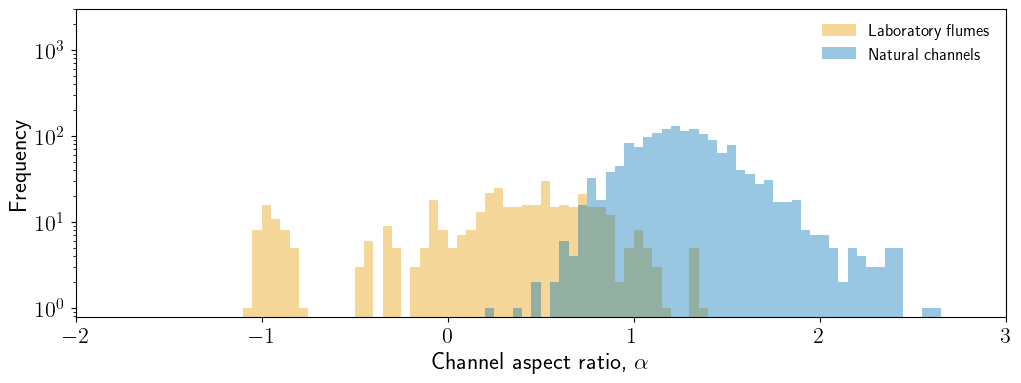

In [6]:
fig = plt.figure(figsize=(figwidth, figwidth/3))

x = 'alpha'
stat = 'frequency'
kde = True
log_scale = True
binrange = (-1.25, 3)
binwidth = 0.05
alpha = 0.4
color = {'river': '#0072B2', 'flume': '#E69F00'}

# original figure created with seaborn (sns)
# sns.histplot(df, color=color['flume'], x=x, kde=kde, alpha=alpha, log_scale=log_scale, binrange=binrange, binwidth=binwidth, stat=stat)
# sns.histplot(df_river, color=color['river'], x=x, kde=kde, alpha=alpha, log_scale=log_scale, binrange=binrange, binwidth=binwidth, stat=stat)

# Histogram for 'df' (flume data)
data_flume = np.log10(df[x].dropna()) # Drop NaN values
bins = np.arange(binrange[0], binrange[1] + binwidth, binwidth)
plt.hist(
    data_flume,
    bins=bins,
    color=color['flume'],
    alpha=alpha,
    log=log_scale,
    density=(stat == 'density'),
    label='Laboratory flumes'
)

# Histogram for 'df_river' (river data)
data_river = np.log10(df_river[x].dropna())  # Drop NaN values
plt.hist(
    data_river,
    bins=bins,
    color=color['river'],
    alpha=alpha,
    log=log_scale,
    density=(stat == 'density'),
    label='Natural channels'
)

# Set axis limits and labels
plt.xlim(-2, 3)
plt.ylim(0, 3000)
plt.ylabel('Frequency')
plt.xlabel('Channel aspect ratio, $\\alpha$')
plt.legend(loc=1, fancybox=True, framealpha=0)

##### Figure 2

AttributeError: 'DataFrame' object has no attribute 'markersize'

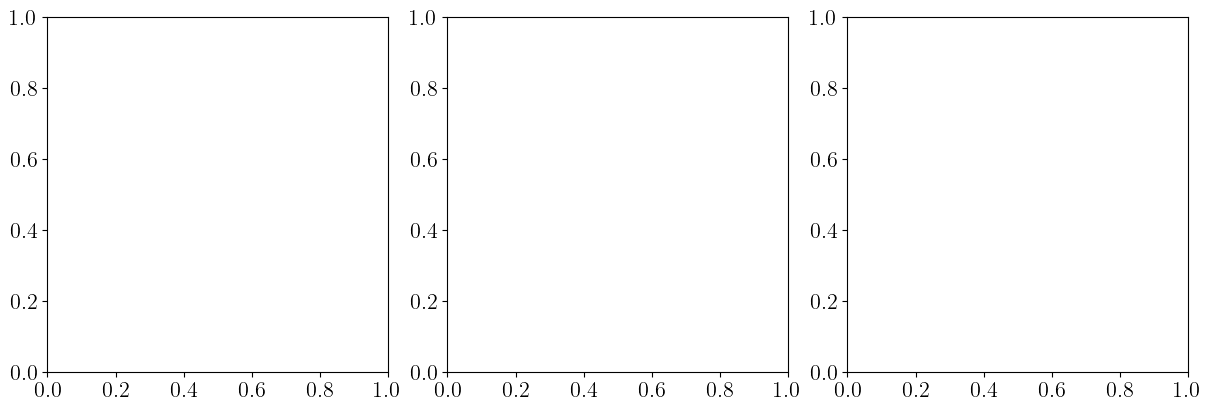

In [7]:
fig, (ax0, ax1, ax2) = plt.subplots(nrows=1, ncols=3, sharex=False, sharey=False, figsize=(figwidth, figwidth/3), layout='constrained')
if global_cmap == 'cividis':
    cmaplines = mpl.cm.get_cmap('viridis')
elif global_cmap == 'viridis':
    cmaplines = mpl.cm.get_cmap('cividis')
    
# Panel a
vmin, vmax = 0.1, 10
for key, group in df.groupby('data_source'):
    if key == 'Song, 1994': continue
    if key == 'New exps':
        ax0.scatter(group.tau8, group.q8, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], edgecolor='k', zorder=1)
    else:
        scatter0 = ax0.scatter(group.tau8, group.q8, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], zorder=0)

x = np.logspace(np.log10(0.0496),0.5,1000)
ax0.loglog(x, wp_func(x), 'k--', label='Best fit MPM function', lw=1.2)

# Panel b
vmin, vmax = 0.03, 3
for key, group in df.groupby('data_source'):
    # if key == 'Song, 1994': continue
    if key == 'New exps':
        scatter1 = ax1.scatter(group.alpha, group.q8, c='k', s=group.markersize, marker=group.m.values[0], label='{}'.format(key), edgecolor='k', zorder=1)
    else:
        scatter1 = ax1.scatter(group.alpha, group.q8, c='k', s=group.markersize, marker=group.m.values[0], label='{}'.format(key))

# Panel c
vmin, vmax = -0.1, 1.1
for key, group in df.groupby('data_source'):
    if key == 'Williams, 1970': zorder = 1
    else: zorder = 2
    twt = calc_FVB(group.f, group.alpha, group.Re, output='twt')
    y = group.tau_m/group.tau
    if key == 'Song, 1994':
        scatter2 = ax2.scatter(group.alpha+1000, y, c=twt, cmap=cmaplines, norm=mcolors.Normalize(vmin=vmin, vmax=vmax), alpha=1, s=group.markersize/3, marker=group.m.values[0], zorder=zorder)
    elif key == 'New exps':
        ax2.scatter(group.alpha, y, c='k', alpha=0.7, s=group.markersize/3, marker=group.m.values[0], edgecolor='k', zorder=3)
    else:
        ax2.scatter(group.alpha, y, c='k', alpha=0.7, s=group.markersize/3, marker=group.m.values[0], zorder=zorder)
    
# plot tauinf/tauinf
x = np.logspace(-2,2,100)
ax2.loglog(x, np.ones_like(x), 'k-', lw=1.2, zorder=4, label='Upper bound ($\\tau = \\tau_\infty$)')
# plot FRtau_inf/tauinf
delta_tau_FR = lambda x: 1/(1 + 2/x)
ax2.loglog(x, delta_tau_FR(x), 'k-.', lw=1.2, zorder=4, label='Lower bound ($\\tau = \\rho g RS$)')

# plot FWFRtau_inf/tauinf
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
delta_tau = lambda x, twt: 1 - twt/(1+x/2)
twtvals = np.linspace(vmin, vmax, 25)
for twt in twtvals:
    ax2.loglog(x, delta_tau(x, twt), '-', lw=0.8, color=cmaplines(norm(twt)), zorder=0)  

# figure finishings
ax0.set_xlabel('Dimensionless bed stress, $\\tau^*_\infty$')
ax0.set_ylabel('Dimensionless sediment flux, $q^*$')
ax1.set_xlabel('Aspect ratio, $\\alpha$')
ax1.set_ylabel('Dimensionless sediment flux, $q^*$')
ax2.set_xlabel('Aspect ratio, $\\alpha$')
ax2.set_ylabel('Sidewall correction, $F_{q_s} = \\tau_{q_s}/\\tau_\infty$')

cax0 = ax0.inset_axes([0.5, 0.2, 0.5, 0.04])
fig.colorbar(scatter0, cax=cax0, orientation='horizontal', label='$\\alpha$')

# divider = make_axes_locatable(ax2)
# cax2 = divider.append_axes("right", size='3%', pad=0.05)
cax2 = ax2.inset_axes([0.5, 0.2, 0.5, 0.04])
cbar = fig.colorbar(scatter2, cax=cax2, orientation='horizontal', label='$\\tau_{wall}/\\tau$')

ax0.set_xlim(0.03, 3)
ax0.set_ylim(1e-4, 100)
ax1.set_xlim(0.05, 50)
ax1.set_ylim(1e-4, 100)
ax2.set_xlim(0.05, 50)
ax2.set_ylim(0.05, 3)

ax1.set_xscale('log'), ax1.set_yscale('log')

ax0.text(0.95, 0.99, 'a', fontsize=15, transform=ax0.transAxes)
# ax0.text(0.6, 0.05, 'Wong & Parker, 2006', fontsize=9, transform=ax0.transAxes)
ax1.text(0.95, 0.99, 'b', fontsize=15, transform=ax1.transAxes)
ax2.text(0.95, 0.99, 'c', fontsize=15, transform=ax2.transAxes)
# ax2.text(0.15, .94, '$F_{q_s}$ as $f(\\tau_{wall}/\\tau)$', fontsize=12, transform=ax2.transAxes)
# x = np.linspace(0.07,0.12,10)
# ax2.loglog(x, 1.7*np.ones_like(x), c=mpl.cm.get_cmap(global_cmap)(0.5), lw=0.8)

ax0.legend(frameon=False, loc=2)
ax1.legend(frameon=False, loc=2, ncols=2, fontsize=9)
ax1.legend_.set_bbox_to_anchor((0, 1.01))
ax2.legend(frameon=False, loc=2, ncols=1)
ax2.legend_.set_bbox_to_anchor((0, 1.03))

##### Figure 3

In [ ]:
fig, ((ax0, ax1), (ax2, ax3)) = plt.subplots(nrows=2, ncols=2, sharex=True, sharey=True, figsize=(figwidth, figwidth/1.7), layout='constrained')
axs = [ax0, ax1, ax2, ax3]
vmin, vmax = 0.02, 2

def fvb_lim(alpha, Re):
    a, b = 0.018409368, 0.224072094
    return (9*a / (1 + alpha/2)) * ss.lambertw((3/a)*(1+alpha/2)*b**3*Re)**(-2)

def fg_lim(alpha, ro):
    beta = (3/4/kappa - 1/kappa/np.pi**2)**2
    phi = np.exp(-(alpha/np.pi)**(3/2))
    psi = beta + (2/alpha) * (np.log(ro*np.exp(-1))/kappa - (1 + phi)**3/12/kappa + ((1 + np.sqrt(phi))/2)*(1+np.sin(np.pi*phi)/(np.pi*(1+phi))))**2 
    return 1 / psi / (1 + alpha/2)

ro = 340
Re = 4e4

# panel a and b
for key, group in df.groupby('data_source'):
    # if key == 'Song, 1994': continue
    scatter0 = ax0.scatter(group.alpha, group.f, c=group.tau_m/group.tau, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize*3, marker=group.m.values[0], alpha=0.75)
    ax0.scatter(group.alpha+1000, group.f, c='k', s=group.markersize*3, marker=group.m.values[0], alpha=0.75, label='{}'.format(key))
    scatter0 = ax1.scatter(group.alpha, group.f, c='k', s=group.markersize, marker=group.m.values[0], alpha=0.75)
    scatter0 = ax2.scatter(group.alpha, group.f, c='k', s=group.markersize, marker=group.m.values[0], alpha=0.75)
    scatter0 = ax3.scatter(group.alpha, group.f, c='k', s=group.markersize, marker=group.m.values[0], alpha=0.75)
    
# I calculate this for 10000 values in the publication (takes a while)
alphas = np.linspace(0.05,50,1000) 
# alphas = np.linspace(0.05,50,10000) 
# I calculate this for 2500 values in the publication (takes a while)
fs = np.linspace(0.0008,0.02,250) 
# fs = np.linspace(0.0008,0.02,2500) 

extent = [alphas[0], alphas[-1], fs[0], fs[-1]]
FRs = np.zeros((len(fs), len(alphas)))
for i, f in enumerate(fs):
    for j, alpha in enumerate(alphas):
        FRs[i,j] = calc_FR(alpha) 
im1 = ax1.imshow(FRs, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), extent=extent, aspect='auto', origin='lower', cmap=global_cmap)
   
# panel c and d
FGs = np.zeros((len(fs), len(alphas)))
FVBs = np.zeros((len(fs), len(alphas)))
for i, f in enumerate(fs):
    for j, alpha in enumerate(alphas):
        FVBs[i,j] = calc_FVB(f, alpha, Re) 
        FGs[i,j] = calc_FG(f, alpha, ro) 
    
im2 = ax2.imshow(FVBs, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), extent=extent, aspect='auto', origin='lower', cmap=global_cmap)
im3 = ax3.imshow(FGs, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), extent=extent, aspect='auto', origin='lower', cmap=global_cmap)

# mask = np.where((FVBs/FGs < 1/1.2) | (FVBs/FGs > 1.2), 0, 1)
# mask = np.where(np.isfinite(FGs), mask, np.nan)
# ax0.contourf(mask, extent=extent, levels=[0.99, 1], colors='black', alpha=0.1, zorder=10)
# ax0.contour(mask, extent=extent, levels=[0.99], colors='black', linewidths=0.5, zorder=0)

ax2.plot(alphas, fvb_lim(alphas, Re), 'k--', lw=1)
ax3.plot(alphas, fg_lim(alphas, ro), 'k--', lw=1)
ax3.fill_between(alphas, np.ones_like(alphas)*extent[2], fg_lim(alphas, ro), color='none', hatch='...', edgecolor='k', lw=0.25, alpha=0.25)

# figure finishings
ax0.legend(ncols=2, frameon=False)

ax0.set_ylabel('Friction factor, $f$')
ax2.set_ylabel('Friction factor, $f$')

ax2.set_xlabel('Aspect ratio, $\\alpha$')
ax3.set_xlabel('Aspect ratio, $\\alpha$')

cbar = fig.colorbar(im2, ax=axs, label='Sidwall correction, $F$', pad=0.025)

bboxdict = dict(facecolor='white', edgecolor='none', pad=0.25, alpha=0.8, boxstyle='round')
ax0.text(0.97, 0.94, 'a', fontsize=15, transform=ax0.transAxes)
ax0.text(0.05, 0.9, '$F_{q_s} = \\tau_{q_s}/\\tau_\infty$ (flux-inferred)', fontsize=16, transform=ax0.transAxes, bbox=bboxdict)
ax1.text(0.97, 0.94, 'b', fontsize=15, transform=ax1.transAxes)
ax1.text(0.05, 0.9, '$F_R$ (hydraulic radius)', fontsize=16, transform=ax1.transAxes, bbox=bboxdict)
ax2.text(0.97, 0.94, 'c', fontsize=15, transform=ax2.transAxes)
ax2.text(0.05, 0.9, '$F_{VB}$ (Vanoni-Brooks)', fontsize=16, transform=ax2.transAxes, bbox=bboxdict)
ax2.text(0.95, 0.1, '$Re = 40,000$', ha='right', fontsize=16, transform=ax2.transAxes, bbox=bboxdict)
ax3.text(0.97, 0.94, 'd', fontsize=15, transform=ax3.transAxes)
ax3.text(0.05, 0.9, '$F_G$ (Guo)', fontsize=16, transform=ax3.transAxes, bbox=bboxdict)
ax3.text(0.95, 0.1, '$r_o = 340$', ha='right', fontsize=16, transform=ax3.transAxes, bbox=bboxdict)

ax0.set_xlim(extent[0], extent[1])
ax0.set_ylim(extent[2], extent[3])
ax0.set_xscale('log'), ax0.set_yscale('log')

##### Figure 4

In [ ]:
fig, ((ax0, ax1), (ax2, ax3)) = plt.subplots(nrows=2, ncols=2, sharex='col', sharey=False, figsize=(figwidth, figwidth/1.7), layout='constrained')
axs = [ax0, ax1, ax2, ax3]
vmin, vmax = 0.1, 10

# panel a
for key, group in df.groupby('data_source'):
    if key == 'Deal et al., 2023':  
        ax2.scatter(group.tau_m, group.FG * group.tau, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], zorder=1)
        ax0.scatter(group.tau_m, group.FVB * group.tau, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], zorder=1)
        ax0.scatter(group.tau_m+1000, group.FVB * group.tau, c='k', s=group.markersize, marker=group.m.values[0], label='{}'.format(key), zorder=1)
    elif key == 'New exps':
        ax2.scatter(group.tau_m, group.FG * group.tau, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], edgecolor='k', zorder=2)
        ax0.scatter(group.tau_m, group.FVB * group.tau, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], edgecolor='k', zorder=2)
        ax0.scatter(group.tau_m+1000, group.FVB * group.tau, c='k', s=group.markersize, marker=group.m.values[0], edgecolor='k', label='{}'.format(key), zorder=2)
    else:
        scatter2 = ax2.scatter(group.tau_m, group.FG * group.tau, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], zorder=0)
        scatter0 = ax0.scatter(group.tau_m, group.FVB * group.tau, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], zorder=0)
        ax0.scatter(group.tau_m+1000, group.FVB * group.tau, c='k', s=group.markersize, marker=group.m.values[0], label='{}'.format(key), zorder=0)
        
# plot 1:1, 2:1, 1:2 lines        
x = np.linspace(0, 100)
ax2.loglog(x, 2*x, 'k:')
ax0.loglog(x, 2*x, 'k:')
ax2.loglog(x, x/2, 'k:', label='2:1 or 1:2')
ax0.loglog(x, x/2, 'k:', label='2:1 or 1:2')
ax2.loglog(x, x, 'k--', label='1:1')
ax0.loglog(x, x, 'k--', label='1:1')

# panel b
for key, group in df.groupby('data_source'):
    tauG = group.FG * group.tau
    tauVB = group.FVB * group.tau
    if key == 'New exps':
        ax3.scatter(group.alpha, group.tau_m/tauG, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], edgecolor='k', label='{}'.format(key), zorder=2)
        ax1.scatter(group.alpha, group.tau_m/tauVB, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], edgecolor='k', label='{}'.format(key), zorder=2)
    else:
        scatter3 = ax3.scatter(group.alpha, group.tau_m/tauG, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], label='{}'.format(key), zorder=0)
        scatter1 = ax1.scatter(group.alpha, group.tau_m/tauVB, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], label='{}'.format(key), zorder=0)
    
# plot 1:1, 2:1, 1:2 lines
x = np.linspace(0, 50, 100)
ax3.plot(x, np.ones_like(x), 'k--', lw=0.8)
ax1.plot(x, np.ones_like(x), 'k--', lw=0.8)
ax3.plot(x, 2*np.ones_like(x), 'k:', lw=0.8)
ax1.plot(x, 2*np.ones_like(x), 'k:', lw=0.8)
ax3.plot(x, 0.5*np.ones_like(x), 'k:', lw=0.8)
ax1.plot(x, 0.5*np.ones_like(x), 'k:', lw=0.8)

# figure finishings
ax0.text(0.97, 0.93, 'a', fontsize=15, transform=ax0.transAxes)
ax1.text(0.97, 0.93, 'b', fontsize=15, transform=ax1.transAxes)
ax2.text(0.97, 0.93, 'c', fontsize=15, transform=ax2.transAxes)
ax3.text(0.97, 0.93, 'd', fontsize=15, transform=ax3.transAxes)

ax2.set_ylabel('Corrected stress, $F_G\\tau_{\infty}$')
ax3.set_ylabel('Relative error, $\\tau_{q_s}/(F_G\\tau_{\infty})$')
ax0.set_ylabel('Corrected stress, $F_{VB}\\tau_{\infty}$')
ax1.set_ylabel('Relative error, $\\tau_{q_s}/(F_{VB}\\tau_{\infty})$')
ax2.set_xlabel('Flux-inferred stress, $\\tau_{q_s}$')
ax3.set_xlabel('Aspect ratio, $\\alpha$')

ax3.set_xscale('log')
ax3.set_yscale('log')
ax1.set_yscale('log')
ax1.set_yscale('log')

ax2.set_xlim(0.5, 100)
ax2.set_ylim(0.5, 100)
ax3.set_xlim(0.05, 30)
ax3.set_ylim(0.1, 10)
ax0.set_xlim(0.5, 100)
ax0.set_ylim(0.5, 100)
ax1.set_xlim(0.05, 30)
ax1.set_ylim(0.1, 10)

ax0.legend(frameon=False, loc=2)
ax2.text(0.95, .1, 'Guo', ha='right', fontsize=16, transform=ax2.transAxes)
ax3.text(0.95, .1, 'Guo', ha='right', fontsize=16, transform=ax3.transAxes)
ax0.text(0.95, .1, 'Vanoni-Brooks', ha='right', fontsize=16, transform=ax0.transAxes)
ax1.text(0.95, .1, 'Vanoni-Brooks', ha='right', fontsize=16, transform=ax1.transAxes)

# cbar = fig.colorbar(scatter0, ax=axs, label='Aspect ratio, $\\alpha$', pad=0.025)
cax2 = ax2.inset_axes([0.05, 0.9, 0.5, 0.04])
cbar = fig.colorbar(scatter2, cax=cax2, orientation='horizontal', label='Aspect ratio, $\\alpha$')

##### Figure 5

In [ ]:
fig, (ax0, ax1) = plt.subplots(nrows=1, ncols=2, sharex=False, sharey=True, figsize=(figwidth, figwidth/3), layout='constrained')
axs = [ax0, ax1]

# panel a
for key, group in df.groupby('data_source'):
    if key == 'Song, 1994': continue
    if key == 'Deal et al., 2023':
        ax0.scatter(group.FVB * group.tau8+1000, group.q8, c='k', s=group.markersize, marker=group.m.values[0], label='{}'.format(key), zorder=1)
        ax0.scatter(group.FVB * group.tau8, group.q8, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], zorder=1)
    elif key == 'New exps':
        ax0.scatter(group.FVB * group.tau8+1000, group.q8, c='k', s=group.markersize, marker=group.m.values[0], label='{}'.format(key), zorder=2, edgecolor='k')
        ax0.scatter(group.FVB * group.tau8, group.q8, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], zorder=2, edgecolor='k')
    else:
        scatter0 = ax0.scatter(group.FVB * group.tau8+1000, group.q8, c='k', s=group.markersize, marker=group.m.values[0], label='{}'.format(key), zorder=0)
        scatter0 = ax0.scatter(group.FVB * group.tau8, group.q8, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], zorder=0)
        
# plot Wong and Parker    
x = np.logspace(np.log10(0.0496),0.5,1000)
ax0.loglog(x, wp_func(x), 'k--')

# panel b
vmin, vmax = 0.1, 10
for key, group in df.groupby('data_source'):
    if key == 'Song, 1994': continue   
    if key == 'Deal et al., 2023':
        cf = group.FG / group.FR
        print(cf.mean(), cf.min(), cf.max(), cf.std())
        ax1.scatter(group.FG * group.tau8, group.q8, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], zorder=1)
    elif key == 'New exps':
        ax1.scatter(group.FG * group.tau8, group.q8, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], zorder=2, edgecolor='k')
    else:
        scatter1 = ax1.scatter(group.FG * group.tau8, group.q8, c=group.alpha, cmap=global_cmap, norm=mcolors.LogNorm(vmin=vmin, vmax=vmax), s=group.markersize, marker=group.m.values[0], zorder=0)
  
# plot Wong and Parker    
ax1.loglog(x, wp_func(x), 'k--', label='Best fit MPM function')

# figure finishings
ax0.text(0.9, 0.95, 'a', fontsize=15, transform=ax0.transAxes)
ax0.text(0.1, 0.9, 'Vanoni-Brooks', fontsize=16, transform=ax0.transAxes)
ax1.text(0.9, 0.95, 'b', fontsize=15, transform=ax1.transAxes)
ax1.text(0.1, 0.9, 'Guo', fontsize=16, transform=ax1.transAxes)

ax0.set_xlabel('Corrected dimensionless bed stress, $F_{VB}\\tau_\infty^*$')
ax0.set_ylabel('Dimensionless sediment flux, $q^*$')
ax1.set_xlabel('Corrected dimensionless bed stress, $F_G\\tau_\infty^*$')

ax0.legend(frameon=False, loc=4)
ax1.legend(frameon=False, loc=4)
ax1.legend_.set_bbox_to_anchor((1, 0.25))

ax0.set_xlim(0.01, 1)
ax0.set_ylim(.5e-4, .5e2)
ax1.set_xlim(0.01, 1)
ax1.set_ylim(.5e-4, .5e2)

# cbar = fig.colorbar(scatter1, ax=axs, label='Aspect ratio, $\\alpha$')
cax1 = ax1.inset_axes([0.5, 0.2, 0.47, 0.04])
cbar = fig.colorbar(scatter1, cax=cax1, orientation='horizontal', label='Aspect ratio, $\\alpha$')

##### Figure 6

In [ ]:
fig, ((ax0, ax1), (ax2, ax3), (ax4, ax5)) = plt.subplots(nrows=3, ncols=2, sharex=True, sharey=True, figsize=(figwidth, figwidth), layout='constrained')
fig.set_constrained_layout_pads(h_pad=0.25, w_pad=0.25)  # Adjust horizontal and vertical padding

ax2b = inset_axes(ax2, width="40%", height="40%", loc='upper left', borderpad=1)
ax4b = inset_axes(ax4, width="40%", height="40%", loc='upper left', borderpad=1)
# define special figure parameters
marker = {'sphere': 'o', 'gravel': '+'}
color = {'wide': '#0072B2', 'narrow': '#E69F00'}
ms = {'sphere': 5, 'gravel': 8}
labels = {'narrowsphere': 'spheres, narrow ($\\alpha \\approx 0.1$)', 'narrowgravel': 'gravel, narrow ($\\alpha \\approx 0.1$)', 'widesphere': 'spheres, wide ($\\alpha \\approx 1.2$)', 'widegravel': 'gravel, wide ($\\alpha \\approx 1.2$)'}
lwfunc = 0.8

for key, group in df.groupby('data_source'):
    if key == 'Deal et al., 2023' or 'New experiments':
        for gkey, grain in group.groupby('grain_kind'):
            if (gkey == 'sphere') or (gkey == 'gravel'):
                for fkey, flume in grain.groupby('flume_width'):
                    # panel a
                    ax0.plot(grain.FR * grain.tau8, grain.q8, '.', color=color[fkey], marker=marker[gkey], ms=ms[gkey], label=labels[fkey+gkey])
                    
                    # panel b
                    ax1.plot(grain.FS * grain.FR * grain.tau8, grain.q8, '.', color=color[fkey], marker=marker[gkey], ms=ms[gkey])
                    
                    if key == 'Deal et al., 2023': 
                        print(fkey, (grain.FG/grain.FR).mean(), (grain.FG/grain.FR).std())
                        a, c, l = 0.5, 'gray', labels[fkey+gkey]
                    else: 
                        a, c, l = 1, color[fkey], None
                    # panel c
                    ax2.plot(grain.FVB * grain.tau8, grain.q8, '.', color=c, marker=marker[gkey], ms=ms[gkey], alpha=a, label=l)
                    
                    # panel d
                    ax3.plot(grain.FVB * grain.FS * grain.tau8, grain.q8, '.', color=c, marker=marker[gkey], ms=ms[gkey], alpha=a)
                    
                    # panel e
                    ax4.plot(grain.FG * grain.tau8, grain.q8, '.', color=color[fkey], marker=marker[gkey], ms=ms[gkey])
                    
                    # panel f
                    ax5.plot(grain.FG * grain.FS * grain.tau8, grain.q8, '.', color=color[fkey], marker=marker[gkey], ms=ms[gkey])
                    
                    # inset to panel c
                    # what we did in the nature paper
                    if fkey == 'narrow': 
                        if gkey == 'sphere':
                            ax2b.plot(2.41 * grain.FR * grain.tau8, grain.q8, '.', color=color[fkey], marker=marker[gkey], ms=ms[gkey], label='$F_C = 2.4F_R$')
                        else:
                            ax2b.plot(2.41 * grain.FR * grain.tau8, grain.q8, '.', color=color[fkey], marker=marker[gkey], ms=ms[gkey])
                            ax2b.plot(3.45e-2, 0.6, '.', color=color[fkey], marker=marker[gkey], ms=ms[gkey])
                    else: 
                        if gkey == 'sphere':
                            ax2b.plot(grain.FVB * grain.tau8, grain.q8, '.', color=color[fkey], marker=marker[gkey], ms=ms[gkey], label='$F_C = F_{VB}$')
                        else:
                            ax2b.plot(grain.FVB * grain.tau8, grain.q8, '.', color=color[fkey], marker=marker[gkey], ms=ms[gkey])
                            ax2b.plot(3.45e-2, 0.13, '.', color=color[fkey], marker=marker[gkey], ms=ms[gkey])
                            
                    # inset to panel e
                    # what we did in the nature paper
                    if fkey == 'narrow': 
                        if gkey == 'sphere':
                            ax4b.plot(2.41 * grain.FR * grain.tau8, grain.q8, '.', color=color[fkey], marker=marker[gkey], ms=ms[gkey], label='$F_C = 2.4F_R$')
                        else:
                            ax4b.plot(2.41 * grain.FR * grain.tau8, grain.q8, '.', color=color[fkey], marker=marker[gkey], ms=ms[gkey])
                            ax4b.plot(3.45e-2, 0.6, '.', color=color[fkey], marker=marker[gkey], ms=ms[gkey])
                    else: 
                        if gkey == 'sphere':
                            ax4b.plot(grain.FG * grain.tau8, grain.q8, '.', color=color[fkey], marker=marker[gkey], ms=ms[gkey], label='$F_C = F_G$')
                        else:
                            ax4b.plot(grain.FG * grain.tau8, grain.q8, '.', color=color[fkey], marker=marker[gkey], ms=ms[gkey])
                            ax4b.plot(3.45e-2, 0.13, '.', color=color[fkey], marker=marker[gkey], ms=ms[gkey])
                     
# plot Best fit
x = np.logspace(np.log10(0.051),0.5,1000)
ax0.loglog(x, wp_func(x), 'k--', lw=lwfunc, label='Best fit MPM function')
ax1.loglog(x, wp_func(x), 'k--', lw=lwfunc)
ax2.loglog(x, wp_func(x), 'k--', lw=lwfunc)
ax3.loglog(x, wp_func(x), 'k--', lw=lwfunc)
ax4.loglog(x, wp_func(x), 'k--', lw=lwfunc)
ax5.loglog(x, wp_func(x), 'k--', lw=lwfunc)
ax2b.loglog(x, wp_func(x), 'k--', lw=lwfunc)
ax4b.loglog(x, wp_func(x), 'k--', lw=lwfunc)

ax0.set_xscale('log'), ax0.set_yscale('log')
ax0.set_ylim(1e-3, 2), ax0.set_xlim(2e-2, .5)
ax3.set_ylim(1e-3, 2), ax3.set_xlim(2e-2, .5)
ax2b.set_ylim(1e-3, 2), ax2b.set_xlim(2e-2, .5)
ax4b.set_ylim(1e-3, 2), ax4b.set_xlim(2e-2, .5)

ax0.set_xlabel(r'$F_R\tau^*_\infty$')
ax1.set_xlabel(r'$F_{shape}F_R\tau^*_\infty$')
ax2.set_xlabel(r'$F_{VB}\tau^*_\infty$')
ax3.set_xlabel(r'$F_{shape}F_{VB}\tau^*_\infty$')
ax4.set_xlabel(r'$F_G\tau^*_\infty$')
ax5.set_xlabel(r'$F_{shape}F_G\tau^*_\infty$')
ax2b.set_xlabel(r'$F_C\tau^*_\infty$', fontsize=11)
ax4b.set_xlabel(r'$F_C\tau^*_\infty$', fontsize=11)
ax0.set_ylabel(r'Dimensionless sediment flux, $q^*$')
ax2.set_ylabel(r'Dimensionless sediment flux, $q^*$')
ax4.set_ylabel(r'Dimensionless sediment flux, $q^*$')

ax0.legend(frameon=False, loc=4)
ax2.legend(frameon=False, loc=4)
ax3.legend(frameon=False, loc=4)
ax2b.legend(frameon=False, loc=2, fontsize=9)
ax2b.tick_params(labelleft=False)
ax2b.set_xscale('log'), ax2b.set_yscale('log')

ax4b.legend(frameon=False, loc=2, fontsize=9)
ax4b.tick_params(labelleft=False)
ax4b.set_xscale('log'), ax2b.set_yscale('log')

ax0.text(0.9, 0.925, 'a', fontsize=15, transform=ax0.transAxes)
ax1.text(0.9, 0.925, 'b', fontsize=15, transform=ax1.transAxes)
ax2.text(0.9, 0.925, 'c', fontsize=15, transform=ax2.transAxes)
ax3.text(0.9, 0.925, 'd', fontsize=15, transform=ax3.transAxes)
ax4.text(0.9, 0.925, 'e', fontsize=15, transform=ax4.transAxes)
ax5.text(0.9, 0.925, 'f', fontsize=15, transform=ax5.transAxes)

# Add a semitransparent box in figure coordinates
highlight_color = 'gray'  # Color of the box
highlight_alpha = 0.075    # Transparency level

# Coordinates for the box in figure coordinates (normalized 0 to 1)
x_locs = [[-0.015, 1.035], [-0.015, 1.035], [-0.015, 1.035], [0.015, 0.52], [0.55, 0.99]] 
y_locs = [[0.015, 0.335], [0.36, 0.66], [0.685, .99], [-0.01, 1.02], [-0.01, 1.02]] 

# Labels for each rectangle
labels = [ "Guo Correction", "Vanoni-Brooks correction", "Hydraulic radius correction", 'Without shape correction', 'With shape correction']

# Add the rectangle to the figure
for i in range(5):
    x_start, x_end = x_locs[i]
    y_start, y_end = y_locs[i]
    rect = Rectangle((x_start, y_start), x_end - x_start, y_end - y_start,
                    transform=fig.transFigure, color=highlight_color, edgecolor='k', alpha=highlight_alpha, zorder=2)
    fig.add_artist(rect)
    
    # Add vertical text at the right edge of the rectangle
    if i < 3: 
        fig.text(
            x_end - 0.01,  # Slightly inside the right edge of the rectangle
            (y_start + y_end) / 2,  # Centered vertically within the rectangle
            labels[i],  # Text label
            fontsize=16,  # Font size
            rotation=90,  # Rotate text vertically
            va='center',  # Vertical alignment
            ha='right',   # Horizontal alignment
        )
    # Add horiztonal text at the top edge of the rectangle
    else:
        fig.text(
            (x_start + x_end) / 2,  # Centered horizontally within the rectangle
            y_end - 0.01,  # Slightly inside the top edge of the rectangle
            labels[i],  # Text label
            fontsize=16,  # Font size
            va='top',  # Vertical alignment
            ha='center',   # Horizontal alignment
        )